# Deploy model and run inference

In [1]:
%pip install "sagemaker>=3,<4" "opencv-python-headless<4.11" six -U

  Using cached scipy-1.15.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)


  Using cached paramiko-5.1.0-py3-none-any.whl.metadata (3.8 kB)


  Using cached pyiceberg-0.12.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (4.7 kB)


  Using cached pyarrow-25.0.1-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (3.0 kB)


  Using cached deepdiff-9.1.0-py3-none-any.whl.metadata (8.4 kB)


  Using cached sagemaker_schema_inference_artifacts-0.0.5-py3-none-any.whl.metadata (2.3 kB)


... (317 outputs left out)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺ 76/77 [sagemaker]

      Successfully uninstalled sagemaker-2.257.7
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺ 76/77 [sagemaker]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77/77 [sagemaker]


Note: you may need to restart the kernel to use updated packages.


**Important:** after the install cell above finishes, restart the kernel (**Kernel > Restart**) and then run the notebook from the top again. The SageMaker SDK version that was already loaded keeps being used until you restart.

This project uses the SageMaker Python SDK **v3** (the `Model`, `EndpointConfig` and `Endpoint` resources from `sagemaker.core` for deployment). SDK v2 classes such as `Estimator`, `TensorFlowModel` and `.deploy()` no longer exist in v3, and this notebook doesn't use them. The next cell checks that v3 is loaded.

In [2]:
from importlib.metadata import version
import sagemaker

sagemaker_version = version("sagemaker")
print(f"SageMaker SDK version: {sagemaker_version}")
# SDK v2 defines sagemaker.__version__, v3 doesn't. If it is still there, v2 is loaded in this kernel.
if not sagemaker_version.startswith("3.") or hasattr(sagemaker, "__version__"):
    raise RuntimeError(
        f"SageMaker SDK {sagemaker_version} is installed, but this notebook needs v3 loaded in the kernel. "
        "Run the install cell above, restart the kernel (Kernel > Restart) and run the notebook from the top again."
    )

SageMaker SDK version: 3.29.0


In [3]:
import os
import glob
import json
import time
import boto3
import cv2
from botocore.exceptions import ClientError
from sagemaker.core import image_uris
from sagemaker.core.common_utils import name_from_base
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.core.resources import Endpoint, EndpointConfig, Model
from sagemaker.core.shapes import ContainerDefinition, ProductionVariant
%matplotlib inline
import matplotlib.pyplot as plt
import visualization_utils as viz_utils

In [4]:
role = get_execution_role()

Now that the Runs are finished, we deploy the **Best model** chosen in [`3_experiment_summary.ipynb`](../1_model_training/3_experiment_summary.ipynb).
That notebook writes `1_model_training/results/best_model.json` with the candidate's name and the S3 path of its `model.tar.gz`, and the cell below reads it.

To deploy another Run instead, set `MODEL_ARTIFACT_OVERRIDE` to its path. You can find the path under **Training > Training jobs > (job) > Output** in the SageMaker web UI, or in `1_model_training/results/<candidate>.json`:

![Example Artifact](../data/example_artifact.png)

In [5]:
# TODO 3: model artifact of the Best model (read from the summary notebook's output)
from pathlib import Path

MODEL_ARTIFACT_OVERRIDE = ""  # e.g. 's3://sagemaker-us-east-1-<account-id>/tf2-od-.../output/model.tar.gz'

best_model_file = Path('../1_model_training/results/best_model.json')
if MODEL_ARTIFACT_OVERRIDE:
    model_artifact = MODEL_ARTIFACT_OVERRIDE
elif best_model_file.is_file():
    best_model = json.loads(best_model_file.read_text())
    model_artifact = best_model['model_artifact']
    print(f"Best model: {best_model['candidate']} (mAP {best_model['mAP']:.3f})")
else:
    raise FileNotFoundError(
        f"{best_model_file} not found. Run 1_model_training/3_experiment_summary.ipynb first, "
        "or set MODEL_ARTIFACT_OVERRIDE to a model.tar.gz path."
    )
print(model_artifact)

Best model: ssd_resnet50_v1_fpn_640 (mAP 0.094)
s3://sagemaker-us-east-1-403723872191/tf2-od-ssd-resnet50-v1-fpn-640/tf2-od-ssd-resnet50-v1-fpn-640-2026-11-05-16-59-55-464/output/model.tar.gz


The cell below checks that `model_artifact` points to an existing `model.tar.gz` file before creating the endpoint. If it fails, check that you copied the full path from a training job with the status **Completed**.

In [6]:
def check_model_artifact(path: str) -> None:
    """Raise a clear error if the model artifact path is empty, malformed or missing."""
    if not path:
        raise ValueError("model_artifact is empty. Paste the S3 model artifact path of your completed training job.")
    if not path.startswith('s3://') or not path.endswith('model.tar.gz'):
        raise ValueError(f"model_artifact should look like s3://<bucket>/<training-job-name>/output/model.tar.gz, got: {path}")
    bucket, key = path[len('s3://'):].split('/', 1)
    try:
        boto3.client('s3').head_object(Bucket=bucket, Key=key)
    except ClientError as e:
        raise FileNotFoundError(
            f"Cannot find {path} ({e.response['Error']['Code']}). "
            "Check that the training job completed and that the path is correct."
        ) from e
    print(f"Found model artifact: {path}")

check_model_artifact(model_artifact)

Found model artifact: s3://sagemaker-us-east-1-403723872191/tf2-od-ssd-resnet50-v1-fpn-640/tf2-od-ssd-resnet50-v1-fpn-640-2026-11-05-16-59-55-464/output/model.tar.gz


Now we can deploy the model. The cell below creates a **new endpoint** in your account on an `ml.g4dn.xlarge` instance, so you don't need to create one in the AWS console. With SDK v3, this takes three steps: a `Model` (the TensorFlow Serving container and your `model.tar.gz`), an `EndpointConfig` (the instance type and count) and the `Endpoint` itself. Creating the endpoint usually takes 5 to 15 minutes. The cell prints the endpoint status every 30 seconds until it is `InService`, and you can only run inference after that.

You can also follow the progress under **Inference > Endpoints** in the SageMaker web UI:

![Example endpoint](../data/example_endpoints.png)

If the endpoint fails, or is still not ready after 30 minutes, the cell stops with an error message. The most common causes are:
* a quota of 0 for `ml.g4dn.xlarge for endpoint usage` (see **Service Quotas > Amazon SageMaker** in the AWS console)
* a wrong `model_artifact` path

Delete the failed endpoint, as well as its endpoint configuration and model, under **Inference** before you try again.


> **Cost:** from the moment this cell runs, the endpoint is billed every hour until you delete it. If any later cell fails, go straight to **Delete the endpoint** at the bottom and run it before you debug.

In [7]:
endpoint_name = name_from_base('tf2-object-detection')
instance_type = 'ml.g4dn.xlarge'
timeout_minutes = 30

# TensorFlow Serving container that matches the TensorFlow version used for training
image_uri = image_uris.retrieve(
    framework='tensorflow',
    region=Session().boto_region_name,
    version='2.8',
    image_scope='inference',
    instance_type=instance_type
)

try:
    model = Model.create(
        model_name=endpoint_name,
        primary_container=ContainerDefinition(image=image_uri, model_data_url=model_artifact),
        execution_role_arn=role
    )
    endpoint_config = EndpointConfig.create(
        endpoint_config_name=endpoint_name,
        production_variants=[ProductionVariant(
            variant_name='AllTraffic',
            model_name=endpoint_name,
            initial_instance_count=1,
            instance_type=instance_type
        )]
    )
    endpoint = Endpoint.create(endpoint_name=endpoint_name, endpoint_config_name=endpoint_name)
except ClientError as e:
    if e.response['Error']['Code'] == 'ResourceLimitExceeded':
        raise RuntimeError(
            "Your account has no quota for an ml.g4dn.xlarge endpoint. Request an increase of "
            "'ml.g4dn.xlarge for endpoint usage' in Service Quotas > Amazon SageMaker."
        ) from e
    raise

# Wait for the endpoint to be ready, with a clear error if it fails or takes too long
start = time.time()
while True:
    endpoint.refresh()
    status = endpoint.endpoint_status
    elapsed = (time.time() - start) / 60
    print(f"[{elapsed:4.1f} min] Endpoint {endpoint_name}: {status}")
    if status == 'InService':
        break
    if status == 'Failed':
        raise RuntimeError(
            f"Endpoint creation failed: {endpoint.failure_reason}\n"
            f"Check the CloudWatch log group /aws/sagemaker/Endpoints/{endpoint_name} for details."
        )
    if elapsed > timeout_minutes:
        raise TimeoutError(
            f"Endpoint is still '{status}' after {timeout_minutes} minutes. Check its status and logs under "
            "Inference > Endpoints in the SageMaker web UI, and delete it before trying again."
        )
    time.sleep(30)

[ 0.0 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 0.5 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 1.0 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 1.5 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 2.0 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 2.5 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


... (2 outputs left out)

[ 4.0 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 4.5 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 5.0 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: Creating


[ 5.5 min] Endpoint tf2-object-detection-2026-11-05-17-38-11-010: InService


The `predict` function below sends a JSON request to the endpoint with `endpoint.invoke()` and returns the decoded JSON response from TensorFlow Serving.

In [8]:
def predict(payload: dict) -> dict:
    """Send a JSON request to the endpoint and return the decoded JSON response."""
    response = endpoint.invoke(
        body=json.dumps(payload),
        content_type='application/json',
        accept='application/json'
    )
    body = response.body
    return json.loads(body.read() if hasattr(body, 'read') else body)

## Run inference

Our model is now deployed and we can query it. We are going to use the images available in `data/test_video` to run inference and generate a video. To do so, we are going to need a few tools:
* we need to sort all the frames by index order (which corresponds to chronological order)
* we need a function to load images into numpy array
* we need a loop to run inference and display the results on the input image

We list the frame paths and sort them by index.

In [9]:
frames_path = sorted(glob.glob('../data/test_video/*.png'), 
                     key = lambda k: int(os.path.basename(k).split('.')[0].split('_')[1]))

We create a small function to load images.

In [10]:
import numpy as np
def load_image(path: str) -> np.ndarray:
    """Read an image from the path and returns a numpy array"""
    cv_img = cv2.imread(path,1).astype('uint8')
    cv_img = cv2.cvtColor(cv_img, cv2.COLOR_BGR2RGB)
    return cv_img

We create a mapping from id to name for visualization purposes.

In [11]:
category_index = {
                    1: {'id': 1, 'name': 'vehicle'}, 
                    2: {'id': 2, 'name': 'pedestrian'},
                    4: {'id': 4, 'name': 'cyclist'}
                }

This is the main loop:
* we load images to numpy
* we query the deployed model
* we display the inference results on the images

In [12]:
def image_file_to_tensor(path):
    cv_img = cv2.imread(path,1).astype('uint8')
    cv_img = cv2.cvtColor(cv_img, cv2.COLOR_BGR2RGB)
    return cv_img

images = []
for idx, path in enumerate(frames_path):
    if idx % 10 == 0:
        print(f'Processed {idx}/{len(frames_path)} images.')
        
    # load image
    img = image_file_to_tensor(path)
    inputs = {'instances': [img.tolist()]}
    
    # run inference and extract results
    detections = predict(inputs)['predictions'][0]
    detection_boxes = np.array(detections['detection_boxes'])
    detection_classes = [int(x) for x in detections['detection_classes']]
    detection_scores = detections['detection_scores']
    
    # display results on image
    image_np_with_detections = \
        viz_utils.visualize_boxes_and_labels_on_image_array(
            img,
            detection_boxes,
            detection_classes,
            detection_scores,
            category_index,
            use_normalized_coordinates=True,
            max_boxes_to_draw=100,
            min_score_thresh=0.6,
            agnostic_mode=False)
    images.append(image_np_with_detections)

Processed 0/100 images.


Processed 10/100 images.


Processed 20/100 images.


Processed 30/100 images.


Processed 40/100 images.


Processed 50/100 images.


Processed 60/100 images.


Processed 70/100 images.


Processed 80/100 images.


Processed 90/100 images.


We can verify that the model worked correctly by displaying elements of the `images` list.

In [13]:
# Re-enable inline plotting. visualization_utils forced the non-interactive 'Agg'
# backend on import, and a bare '%matplotlib inline' does not reliably override it
# once pyplot is initialized, so set it explicitly with force=True.
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline', force=True)

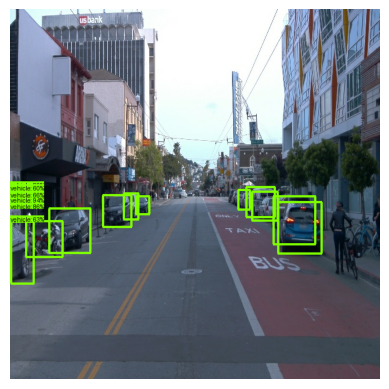

In [14]:
# visualization_utils imports with matplotlib.use('Agg'), a non-interactive backend
# that renders to a buffer instead of the notebook, so plt.imshow() shows nothing.
# Force the inline backend here (force=True overrides the earlier Agg selection),
# then draw.
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline', force=True)
import matplotlib.pyplot as plt

plt.imshow(images[0])
plt.axis('off')
plt.show()

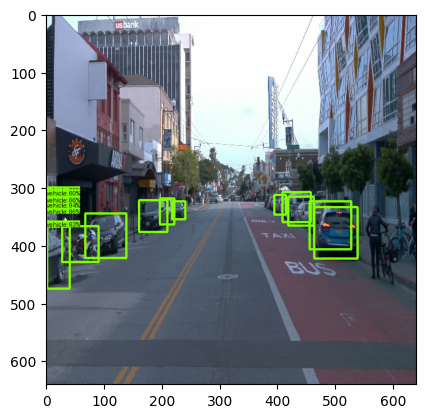

In [15]:
plt.imshow(images[0])

Finally, we can create a video (`output.avi`) with our detections by running the following function.

In [16]:
frame_height = images[0].shape[0]
frame_width = images[0].shape[1]

# VideoWriter expects the frame size as (width, height).
out = cv2.VideoWriter('output.avi', cv2.VideoWriter_fourcc('M','J','P','G'), 10, (frame_width, frame_height))

# Write each frame to the video. No cv2.waitKey/imshow/destroyAllWindows here: this
# runs headless on SageMaker (opencv-python-headless has no GUI backend), so those
# GUI calls raise 'The function is not implemented'.
for image in images:
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    out.write(image)

# Release the writer so the file is finalized on disk.
out.release()
print('Saved output.avi')

Saved output.avi


The video would be stored in the current working directory. You can download it from Sagemaker and run it locally.

## Delete the endpoint

An endpoint is billed for every hour it runs, even when you don't use it. Once you have generated your video, run the cell below to delete the endpoint, the endpoint configuration and the model, then check under **Inference > Endpoints** that the endpoint no longer appears.

In [17]:
endpoint.delete()
endpoint_config.delete()
model.delete()